In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
from pgmpy.estimators import ExpectationMaximization
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, brier_score_loss, roc_auc_score, RocCurveDisplay, roc_curve


Reading data

In [17]:
tele = pd.read_csv("./../data/raw/telemetry.csv", parse_dates=["timestamp"])
labels = pd.read_csv("./../data/processed/labels-3.csv", parse_dates=["timestamp"])

df = tele.merge(labels, on=["timestamp", "machine_id"])
df["delta_temp"] = df["spindle_temp"] - df["ambient_temp"]

vib_hi = df["vibration_rms"].quantile(0.9)
temp_hi = df["delta_temp"].quantile(0.9)
flow_lo = df["coolant_flow"].quantile(0.1)

df["high_vibration"] = (df["vibration_rms"] > vib_hi).astype(int)
df["high_spindle_temp"] = (df["delta_temp"] > temp_hi).astype(int)
df["low_coolant_flow"] = (df["coolant_flow"] < flow_lo).astype(int)
df["spindle_overheat"] = df["spindle_overheat"].astype(int)
df.head()

,timestamp,machine_id,spindle_temp,ambient_temp,vibration_rms,coolant_flow,feed_rate,spindle_speed,load_pct,power_kw,tool_wear,spindle_overheat,delta_temp,high_vibration,high_spindle_temp,low_coolant_flow
0,2025-01-01 00:00:00,M-A,73.96,24.36,0.871,1.050,0.9,3600,0.294,3.193,0.000,0,49.60,0,0,0
1,2025-01-01 00:05:00,M-A,53.38,22.87,0.536,1.083,1.3,800,0.329,2.149,0.000,0,30.51,0,0,0
2,2025-01-01 00:10:00,M-A,58.12,24.59,0.455,1.025,0.9,1200,0.369,2.457,0.001,0,33.53,0,0,0
3,2025-01-01 00:15:00,M-A,58.08,23.05,0.680,0.977,0.7,1200,0.479,2.702,0.001,0,35.03,0,0,0
4,2025-01-01 00:20:00,M-A,55.37,24.28,0.663,1.072,1.1,800,0.328,2.148,0.001,0,31.09,0,0,0


In [25]:
df['spindle_overheat'].value_counts()

spindle_overheat
0    81031
1    22649
Name: count, dtype: int64

In [48]:
train_df, test_df = train_test_split(
    df,
    train_size=0.8,
    random_state=42,
    stratify=df['spindle_overheat']
)

print("ORGINAL LABEL DISTRIBUTION:")
for label, val in df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/df.shape[0]*100, ndigits=2)}%")
print("\n#-----------------------------------------------#\n")

print("TRAIN SET LABEL DISTRIBUTION:")
for label, val in train_df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/train_df.shape[0]*100, ndigits=2)}%")
print("\n#-----------------------------------------------#\n")

print("TEST SET LABEL DISTRIBUTION:")
for label, val in test_df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/test_df.shape[0]*100, ndigits=2)}%")

ORGINAL LABEL DISTRIBUTION:
0: 78.15%
1: 21.85%

#-----------------------------------------------#

TRAIN SET LABEL DISTRIBUTION:
0: 78.16%
1: 21.84%

#-----------------------------------------------#

TEST SET LABEL DISTRIBUTION:
0: 78.15%
1: 21.85%


In [49]:
model1 = DiscreteBayesianNetwork(
    ebunch=[
        ("spindle_overheat", "high_vibration"),
        ("spindle_overheat", "high_spindle_temp"),
        ("spindle_overheat", "low_coolant_flow"),
    ],
)

data1 = train_df[['spindle_overheat', 'high_vibration', 'high_spindle_temp', 'low_coolant_flow']]
model1.fit(data1, estimator=MaximumLikelihoodEstimator)

model1.check_model()

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'spindle_overheat': 'N', 'high_vibration': 'N', 'high_spindle_temp': 'N', 'low_coolant_flow': 'N'}


True

In [51]:
infer1 = VariableElimination(model1)

q1 = infer1.query(
    variables=["spindle_overheat"],
    evidence={"high_vibration": 1, "low_coolant_flow": 1, "high_spindle_temp": 1},
)
print(q1.values)
print(q1)

[0. 1.]
+---------------------+-------------------------+
| spindle_overheat    |   phi(spindle_overheat) |
+=====================+=========================+
| spindle_overheat(0) |                  0.0000 |
+---------------------+-------------------------+
| spindle_overheat(1) |                  1.0000 |
+---------------------+-------------------------+


In [52]:
model2 = DiscreteBayesianNetwork(
    ebunch=[
        ("bearing_wear_high", "high_vibration"),
        ("bearing_wear_high", "spindle_overheat"),
        ("fan_fault", "high_spindle_temp"),
        ("fan_fault", "spindle_overheat"),
        ("clogged_filter", "low_coolant_flow"),
        ("clogged_filter", "spindle_overheat"),
        ("low_cooling_efficiency", "high_spindle_temp"),
        ("low_cooling_efficiency", "spindle_overheat"),
    ],
    latents={
        "bearing_wear_high", 
        "clogged_filter", 
        "fan_fault", 
        "low_cooling_efficiency"
    },
)



em_est = ExpectationMaximization(model=model2, data=data1)

cpds_em = em_est.get_parameters(
    latent_card={lv: 2 for lv in ["bearing_wear_high", "fan_fault", "clogged_filter", "low_cooling_efficiency"]},
    max_iter=1000,
    atol=1e-8,
    n_jobs=1,
    seed=42,
    show_progress=True,
)

model2.add_cpds(*cpds_em)

model2.check_model()

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'spindle_overheat': 'N', 'high_vibration': 'N', 'high_spindle_temp': 'N', 'low_coolant_flow': 'N'}
  5%|▌         | 52/1000 [00:01<00:26, 35.36it/s]


True

In [53]:
infer2 = VariableElimination(model2)

evidence = {
    "high_vibration": 1,
    "high_spindle_temp": 1,
    "low_coolant_flow": 1,
}

# 1) Overheat probability
q_overheat = infer2.query(
    variables=["spindle_overheat"],
    evidence=evidence,
)
print("P(SpindleOverheat | evidence):")
print(q_overheat)

# 2) Posterior over latent causes
q_causes = infer2.query(
    variables=["bearing_wear_high", "fan_fault", "clogged_filter", "low_cooling_efficiency"],
    evidence=evidence,
)
print("\nP(Causes | evidence):")
print(q_causes)

P(SpindleOverheat | evidence):
+---------------------+-------------------------+
| spindle_overheat    |   phi(spindle_overheat) |
+=====================+=========================+
| spindle_overheat(0) |                  0.0000 |
+---------------------+-------------------------+
| spindle_overheat(1) |                  1.0000 |
+---------------------+-------------------------+

P(Causes | evidence):
+----------------------+--------------+-------------------+---------------------------+--------------------------------------------------------------------------+
| bearing_wear_high    | fan_fault    | clogged_filter    | low_cooling_efficiency    |   phi(bearing_wear_high,fan_fault,clogged_filter,low_cooling_efficiency) |
+======================+==============+===================+===========================+==========================================================================+
| bearing_wear_high(0) | fan_fault(0) | clogged_filter(0) | low_cooling_efficiency(0) |                    

In [106]:
def perdict_overheat_prob(infer, evidence):
    """
    Returns the probabilty of spindle_overheat acording to the inference algorithm passed and the evidence
    """
    res = infer.query(
        variables=["spindle_overheat"],
        evidence=evidence,
        show_progress=False,
    )

    return res.values

In [108]:
y_true = []
y_prob_m1 = []
y_prob_m2 = []
log_prob_m1 = []
log_prob_m2 = []

# geting predictions
for _, row in test_df.iterrows():
    evidence = {
        "high_vibration": row["high_vibration"],
        "high_spindle_temp": row["high_spindle_temp"],
        "low_coolant_flow": row["low_coolant_flow"],
    }


    true_label = row["spindle_overheat"]

    y_true.append(row["spindle_overheat"])
    y_prob_m1.append(perdict_overheat_prob(infer=infer1, evidence=evidence)[1])
    y_prob_m2.append(perdict_overheat_prob(infer=infer2, evidence=evidence)[1])
    log_prob_m1.append(np.log(perdict_overheat_prob(infer=infer1, evidence=evidence)[true_label]))
    log_prob_m2.append(np.log(perdict_overheat_prob(infer=infer2, evidence=evidence)[true_label]))


In [109]:
y_pred_m1 = (np.array(y_prob_m1)>=0.5).astype(int)
y_pred_m2 = (np.array(y_prob_m2)>=0.5).astype(int)

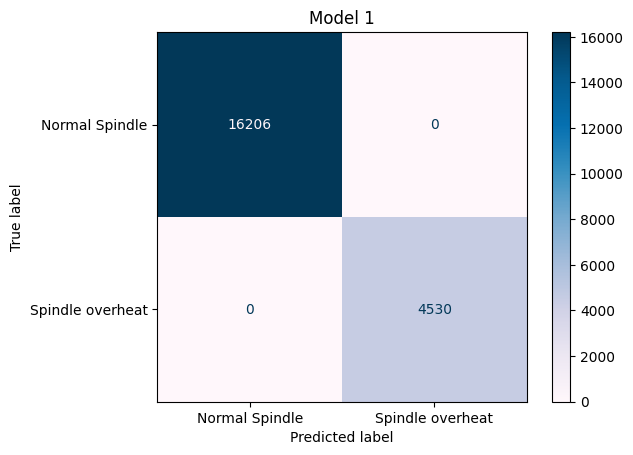

                  precision    recall  f1-score   support

  Normal Spindle       1.00      1.00      1.00     16206
Spindle overheat       1.00      1.00      1.00      4530

        accuracy                           1.00     20736
       macro avg       1.00      1.00      1.00     20736
    weighted avg       1.00      1.00      1.00     20736


#-----------------------------------------------#

Brier score: 0.0014668710477741375
Meadian predictive log probability: -0.04428966824485919
Sum predictive log probability: -717.7583635761882

#-----------------------------------------------#



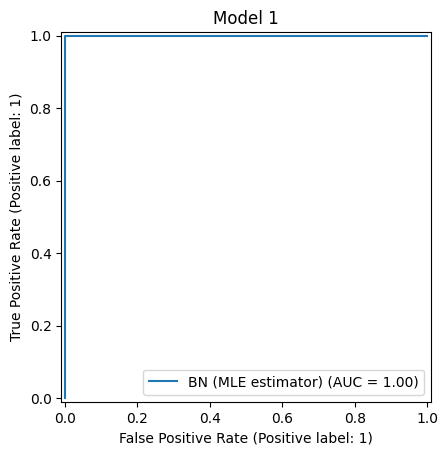

ROC-AUC: 1.0


In [110]:
cm = confusion_matrix(y_true=y_true, y_pred=y_pred_m1)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels= ["Normal Spindle","Spindle overheat"]
)
disp.plot(
    cmap="PuBu",
    )

plt.title("Model 1")
plt.show()

print(classification_report(y_true=y_true, y_pred=y_pred_m1, target_names=["Normal Spindle","Spindle overheat"]))
print("\n#-----------------------------------------------#\n")


brier = brier_score_loss(y_true=y_true, y_proba=y_prob_m1)
print(f"Brier score: {brier}")
print(f"Meadian predictive log probability: {np.median(log_prob_m1)}")
# Using the sum is only possible since the test set is the exact same for both models
print(f"Sum predictive log probability: {np.sum(log_prob_m1)}")


print("\n#-----------------------------------------------#\n")

RocCurveDisplay.from_predictions(y_true=y_true, y_score=y_prob_m1, name="BN (MLE estimator)")
plt.title("Model 1")
plt.show()

roc_auc = roc_auc_score(y_true=y_true, y_score=y_prob_m1)
print(f"ROC-AUC: {roc_auc}")

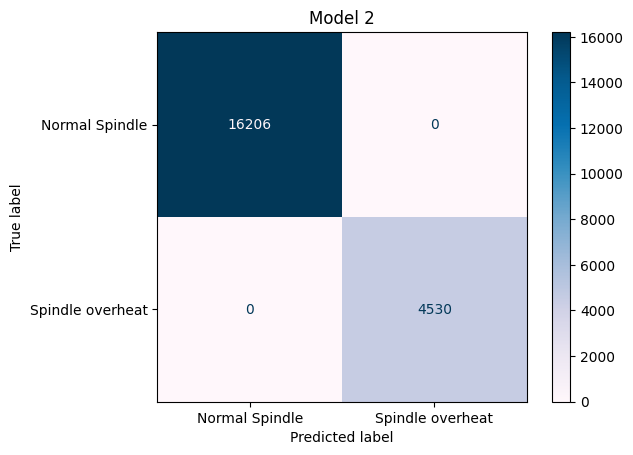

                  precision    recall  f1-score   support

  Normal Spindle       1.00      1.00      1.00     16206
Spindle overheat       1.00      1.00      1.00      4530

        accuracy                           1.00     20736
       macro avg       1.00      1.00      1.00     20736
    weighted avg       1.00      1.00      1.00     20736


#-----------------------------------------------#

Brier score: 9.403037009802778e-16
Median predictive log probability: -4.375944051569629e-12
Sum predictive log probability: -0.0001117163765346002

#-----------------------------------------------#



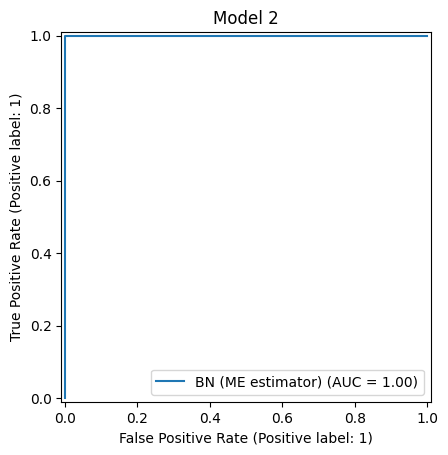

ROC-AUC: 1.0


In [111]:
cm = confusion_matrix(y_true=y_true, y_pred=y_pred_m2)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels= ["Normal Spindle","Spindle overheat"]
)
disp.plot(
    cmap="PuBu",
    )

plt.title("Model 2")
plt.show()

print(classification_report(y_true=y_true, y_pred=y_pred_m2, target_names=["Normal Spindle","Spindle overheat"]))
print("\n#-----------------------------------------------#\n")


brier = brier_score_loss(y_true=y_true, y_proba=y_prob_m2)
print(f"Brier score: {brier}")
print(f"Median predictive log probability: {np.median(log_prob_m2)}")
# Using the sum is only possible since the test set is the exact same for both models
print(f"Sum predictive log probability: {np.sum(log_prob_m2)}")

print("\n#-----------------------------------------------#\n")

RocCurveDisplay.from_predictions(y_true=y_true, y_score=y_prob_m2, name="BN (ME estimator)")
plt.title("Model 2")
plt.show()

roc_auc = roc_auc_score(y_true=y_true, y_score=y_prob_m2)
print(f"ROC-AUC: {roc_auc}")